# Seaborn

Seaborn sits on top of Matplotlib. You hand it the **raw table and the column names**, and it does the grouping, the averaging, the colours and the legend. This chapter draws the NileCart sales table again, this time with Seaborn, and then looks at what those statistical charts compute for you and what they hide.

**Contents**
1. How Seaborn works
2. Relational plots
3. Categorical plots
4. Distribution plots
5. `hue`, palettes and facets
6. Heatmaps and pair plots
7. Reading statistical charts

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
print("seaborn", sns.__version__)

# set the look once, so every chart below stays short
sns.set_theme(style="whitegrid", palette=["#0F766E", "#E89B2D", "#D95D4A", "#152B3C", "#7C8B96"])
plt.rcParams.update({
    "figure.figsize": (8, 4.5),
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.formatter.limits": (-7, 9),      # plain numbers on the axes, no "1e6"
    "legend.frameon": False,
})

sales = pd.read_csv("../data/nilecart/sales.csv", parse_dates=["order_date"])
sales["year"] = sales["order_date"].dt.year
sales["month"] = sales["order_date"].dt.month
print(sales.shape)
sales.head(3)

seaborn 0.13.2
(1466, 20)


,order_id,order_date,customer_id,name,governorate,region,segment,product_id,product_name,category,quantity,unit_price,discount,gross,revenue,unit_cost,profit,status,year,month
0,10002,2024-01-01,176,Fatma Hassan,Cairo,Greater Cairo,Consumer,111,Notebook,Stationery,5.0,63.0,0.00,315.0,315.0,20,215.0,cancelled,2024,1
1,10001,2024-01-01,132,Yasmin Mostafa,Cairo,Greater Cairo,Corporate,101,Laptop,Electronics,9.0,30400.0,0.05,273600.0,259920.0,27200,15120.0,completed,2024,1
2,10004,2024-01-02,131,Yasmin Fawzy,Sharqia,Delta,Corporate,111,Notebook,Stationery,10.0,57.0,0.00,570.0,570.0,20,370.0,completed,2024,1


---
## 1. How Seaborn works

The same chart two ways. In Matplotlib you compute the numbers first, then draw them:

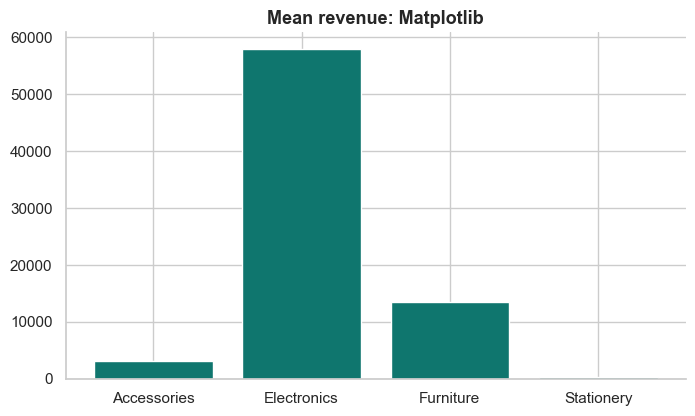

In [2]:
mean_rev = sales.groupby("category")["revenue"].mean()

fig, ax = plt.subplots()
ax.bar(mean_rev.index, mean_rev.values)
ax.set_title("Mean revenue: Matplotlib")
plt.show()

In Seaborn it is one call on the raw table, with no `groupby`:

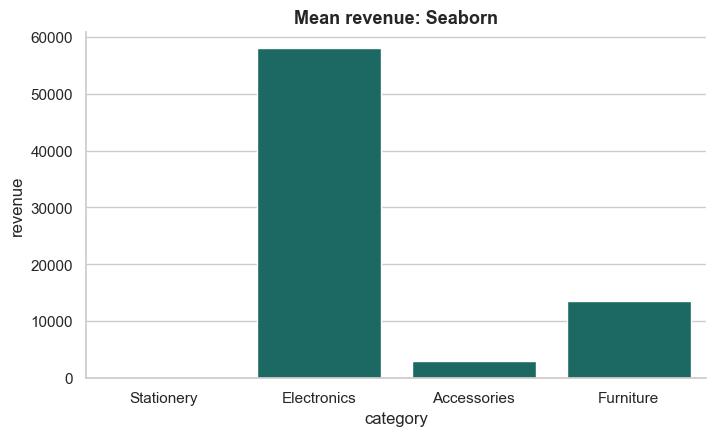

In [3]:
ax = sns.barplot(data=sales, x="category", y="revenue", errorbar=None)
ax.set_title("Mean revenue: Seaborn")
plt.show()

Seaborn has two kinds of functions:

| Kind | Examples | Draws on |
|---|---|---|
| **axes-level** | `scatterplot`, `lineplot`, `barplot`, `histplot`, `boxplot`, `heatmap` | one Axes (pass your own with `ax=`) and returns it |
| **figure-level** | `relplot`, `catplot`, `displot`, `pairplot` | a new Figure with one or more panels, returns a `FacetGrid` |

Because an axes-level function returns a Matplotlib Axes, everything from the Matplotlib chapter (`set_title`, `annotate`, `axhline`, `savefig`) still works on it.

---
## 2. Relational plots

### 2.1 Scatter plot
- **What:** one dot per row, for two numeric columns.
- **When to use:** to see how one column moves with another, for example profit against unit price.

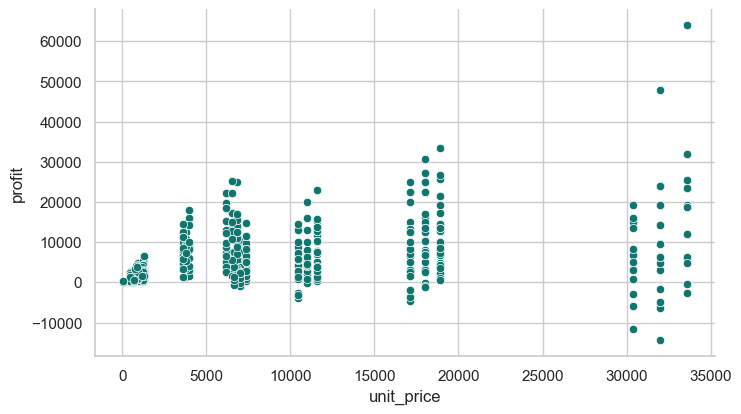

In [4]:
sns.scatterplot(data=sales, x="unit_price", y="profit")
plt.show()

`hue=` colours the dots by a column, and the legend comes for free.

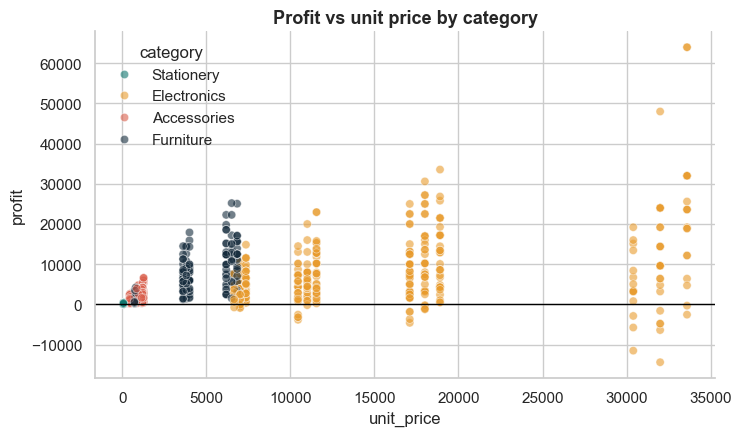

In [5]:
ax = sns.scatterplot(data=sales, x="unit_price", y="profit", hue="category", alpha=0.6)
ax.axhline(0, color="black", linewidth=1)
ax.set_title("Profit vs unit price by category")
plt.show()

### 2.2 Line plot
- **What:** a line over an ordered axis, such as months.
- **When to use:** to show a trend over time.

With **many rows per x value**, `lineplot` draws their **mean**, plus a band for the 95% confidence interval (Section 7.2 explains the band).

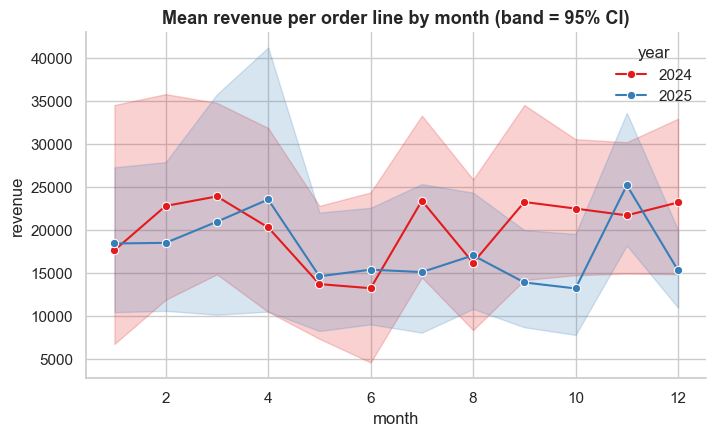

In [6]:
ax = sns.lineplot(data=sales, x="month", y="revenue", hue="year", palette="Set1", marker="o")
ax.set_title("Mean revenue per order line by month (band = 95% CI)")
plt.show()

The bands overlap almost everywhere: the **average order line** is about the same all year. The end-of-year peak in *total* revenue comes from **more orders**, not bigger ones.

For totals, aggregate first:

In [7]:
totals = sales.groupby(["year", "month"], as_index=False)["revenue"].sum()
totals.head(3)

,year,month,revenue
0,2024,1,636209.6
1,2024,2,912799.5
2,2024,3,837362.1


`relplot` is the figure-level version: `col=` gives one panel per year.

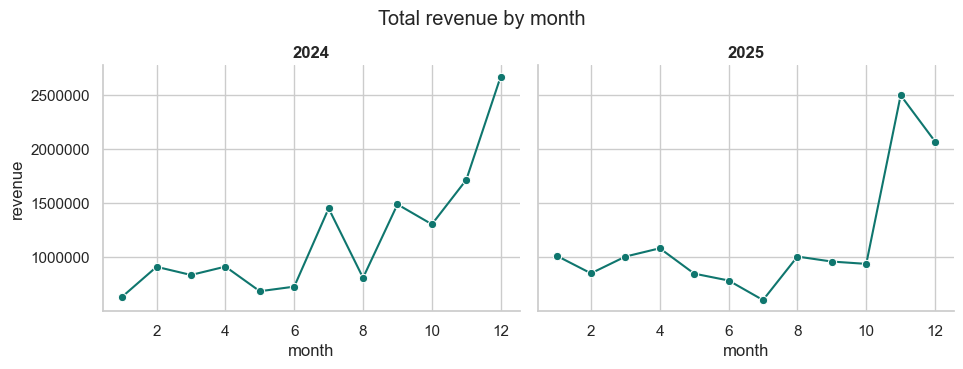

In [8]:
g = sns.relplot(data=totals, x="month", y="revenue", col="year", kind="line", marker="o", height=3.5, aspect=1.4)
g.set_titles("{col_name}")
g.figure.suptitle("Total revenue by month", y=1.05)
plt.show()

---
## 3. Categorical plots

### 3.1 Count plot
- **What:** bars that count the rows of each category.
- **When to use:** for any categorical column, to see which groups are big or small.

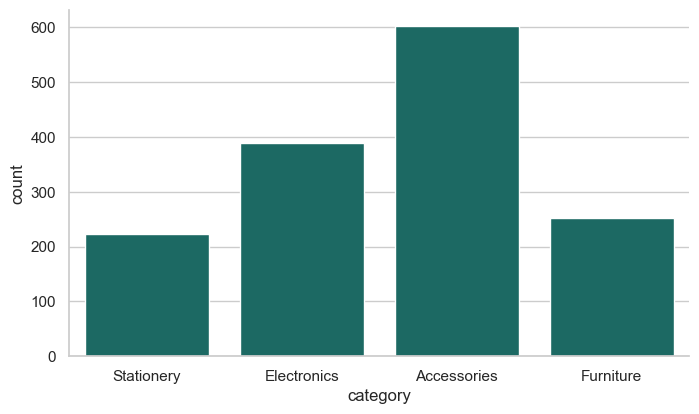

In [9]:
sns.countplot(data=sales, x="category")
plt.show()

`order=` sorts the bars, and `hue=` splits each bar by a second column.

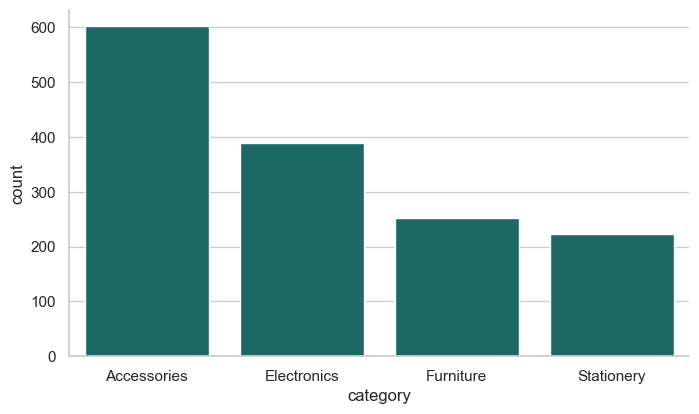

In [10]:
sns.countplot(data=sales, x="category", order=sales["category"].value_counts().index)
plt.show()

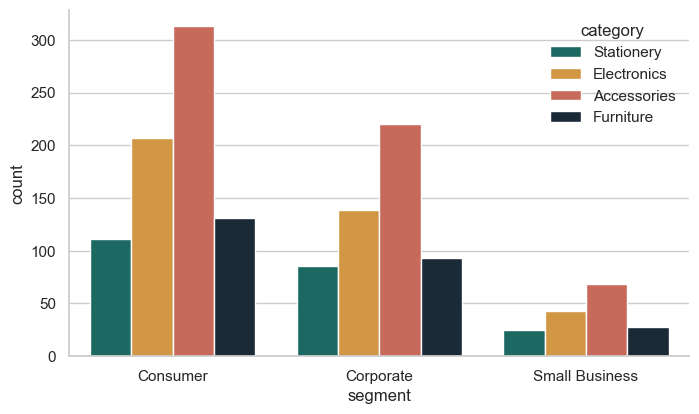

In [11]:
segments = ["Consumer", "Corporate", "Small Business"]
sns.countplot(data=sales, x="segment", hue="category", order=segments)
plt.show()

### 3.2 Bar plot
- **What:** one number per category, the mean by default.
- **When to use:** to compare a numeric column across groups ("who buys more per order?").

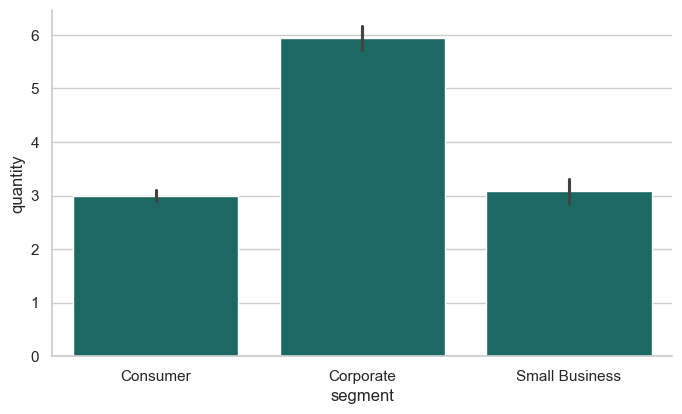

In [12]:
sns.barplot(data=sales, x="segment", y="quantity", order=segments)
plt.show()

The black line on each bar is the **uncertainty** around the mean. `errorbar=` picks which one: the 95% confidence interval (the default), `"sd"`, or `None`. Section 7.2 shows what the two mean.

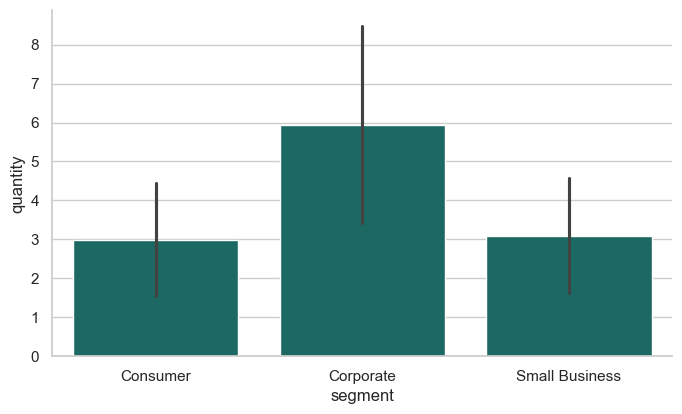

In [13]:
sns.barplot(data=sales, x="segment", y="quantity", order=segments, errorbar="sd")
plt.show()

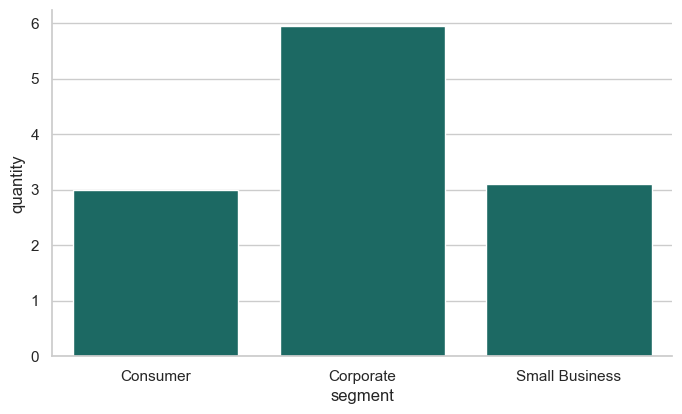

In [14]:
sns.barplot(data=sales, x="segment", y="quantity", order=segments, errorbar=None)
plt.show()

Corporate customers buy about **twice** the quantity per order line (≈ 6 against ≈ 3). The confidence intervals don't overlap, so the difference is not luck.

`estimator=` changes what the bar shows, for example the total instead of the mean:

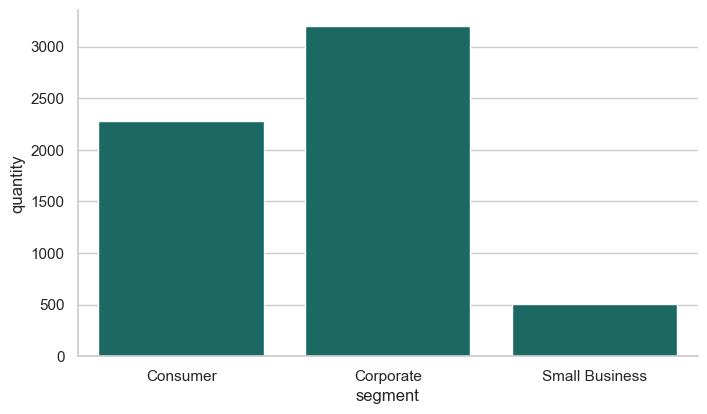

In [15]:
sns.barplot(data=sales, x="segment", y="quantity", order=segments, estimator="sum", errorbar=None)
plt.show()

### 3.3 Box plot and violin plot
- **What:** the whole distribution for each group: five numbers (box), or the full shape (violin).
- **When to use:** to compare distributions across categories, because a bar hides the spread.

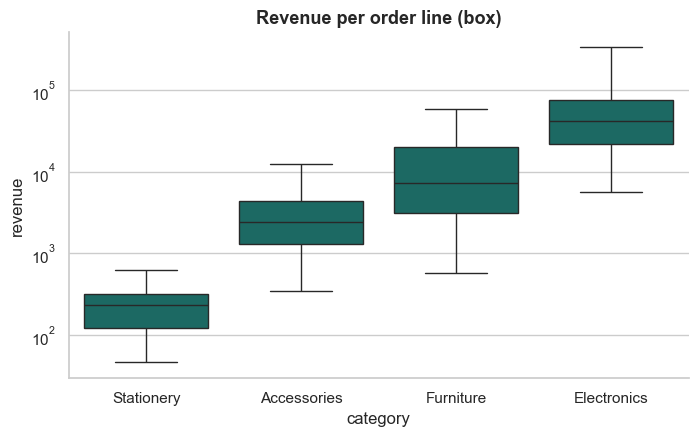

In [16]:
order = ["Stationery", "Accessories", "Furniture", "Electronics"]

ax = sns.boxplot(data=sales, x="category", y="revenue", order=order, log_scale=True)
ax.set_title("Revenue per order line (box)")
plt.show()

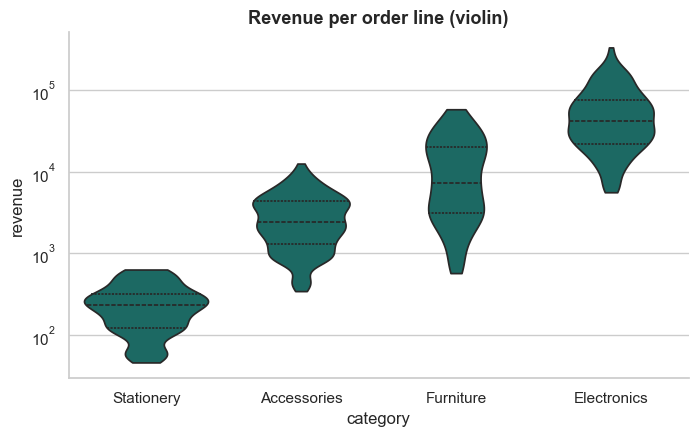

In [17]:
ax = sns.violinplot(data=sales, x="category", y="revenue", order=order, log_scale=True, inner="quart", cut=0)
ax.set_title("Revenue per order line (violin)")
plt.show()

---
## 4. Distribution plots

### 4.1 Histogram
- **What:** bars that count how many values fall in each range.
- **When to use:** as the first look at any numeric column, to see its shape.

median profit: 1638  max: 64000


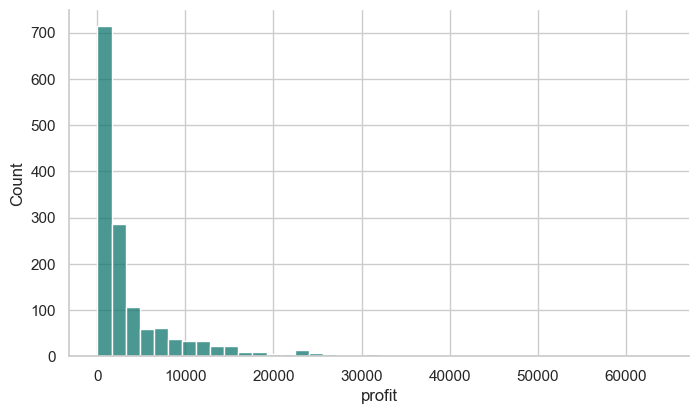

In [18]:
gains = sales[sales["profit"] > 0]
print("median profit:", round(gains["profit"].median()), " max:", round(gains["profit"].max()))

sns.histplot(data=gains, x="profit", bins=40)
plt.show()

Profit per order line is strongly right-skewed: most lines earn a little, a few earn a lot.

`log_scale=True` gives a log axis with log-spaced bins. A log axis needs positive numbers, which is why only the profitable lines are kept.

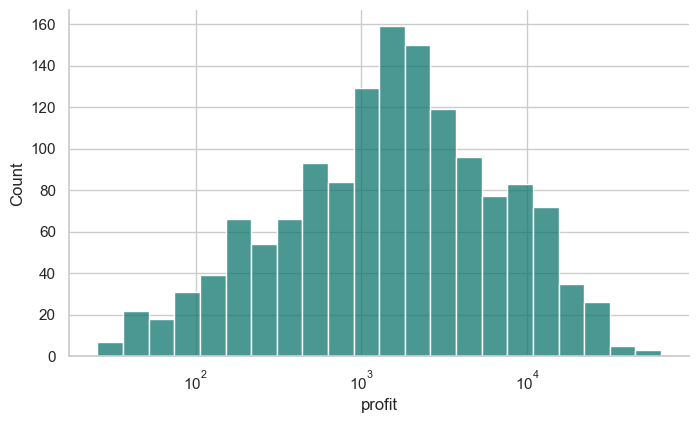

In [19]:
sns.histplot(data=gains, x="profit", log_scale=True)
plt.show()

`kde=True` adds a smooth curve on top.

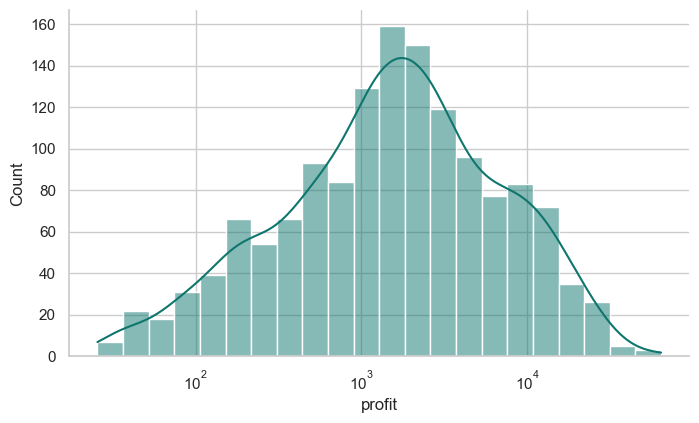

In [20]:
sns.histplot(data=gains, x="profit", log_scale=True, kde=True)
plt.show()

To compare the *shapes* of groups of different sizes, combine `hue=`, `stat="density"` and `common_norm=False`.

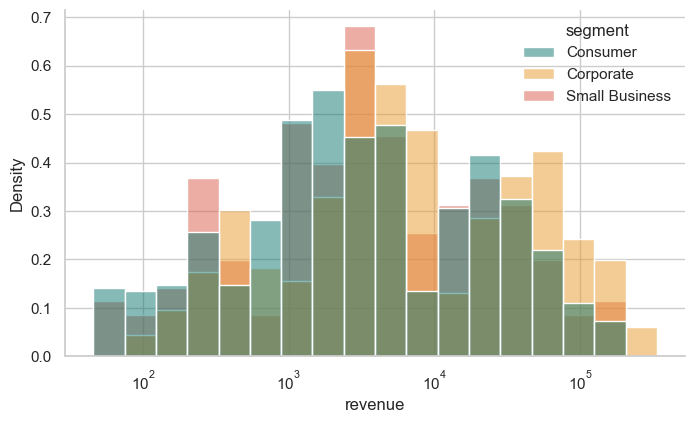

In [21]:
known = sales[sales["segment"].isin(segments)]

sns.histplot(data=known, x="revenue", hue="segment", log_scale=True, stat="density", common_norm=False)
plt.show()

### 4.2 Density plot
- **What:** a smooth curve of the distribution.
- **When to use:** to compare the shapes of a few groups; overlapping curves are easier to read than overlapping bars.

segment
Consumer          3115.0
Corporate         5400.0
Small Business    3425.0
Name: revenue, dtype: float64


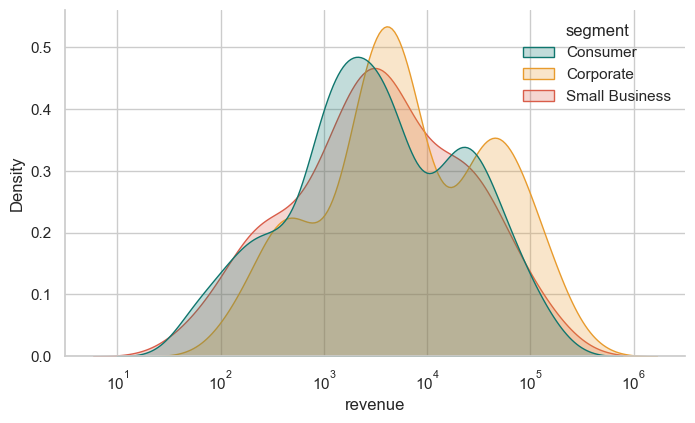

In [22]:
print(known.groupby("segment")["revenue"].median().round())

sns.kdeplot(data=known, x="revenue", hue="segment", log_scale=True, fill=True, common_norm=False)
plt.show()

The Corporate curve sits to the right: its typical order line is worth more.

> ⚠️ A KDE curve is a **smoothed estimate**. It can draw density where there is no data. When in doubt, trust the histogram.

---
## 5. `hue`, palettes and facets

### 5.1 Palettes
Pick the palette that fits the data: `"Set2"` for categories, `"viridis"` for ordered numbers, `"RdBu"` around a centre. A **dict palette** is useful for focus: grey for everything except the one group the chart is about.

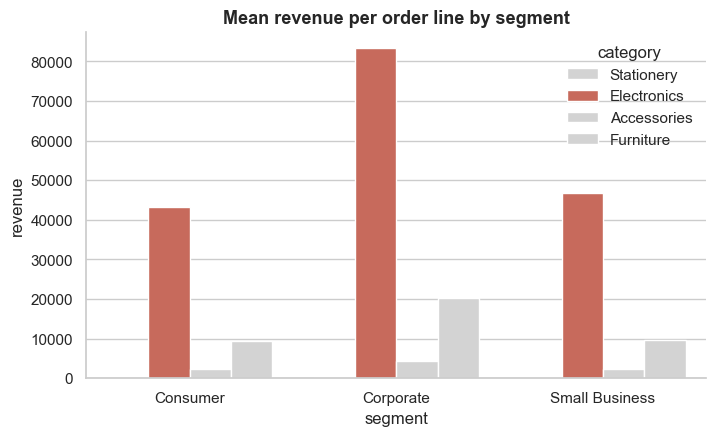

In [23]:
highlight = {"Electronics": "#D95D4A", "Furniture": "lightgrey", "Accessories": "lightgrey", "Stationery": "lightgrey"}

ax = sns.barplot(data=sales, x="segment", y="revenue", hue="category", order=segments,
                 palette=highlight, errorbar=None)
ax.set_title("Mean revenue per order line by segment")
plt.show()

A Corporate Electronics line is worth nearly twice a Consumer one.

### 5.2 Facets
- **What:** the same chart repeated, one panel per group.
- **When to use:** when `hue` gets crowded.

`col=` (and `row=`) work in `relplot`, `catplot` and `displot`.

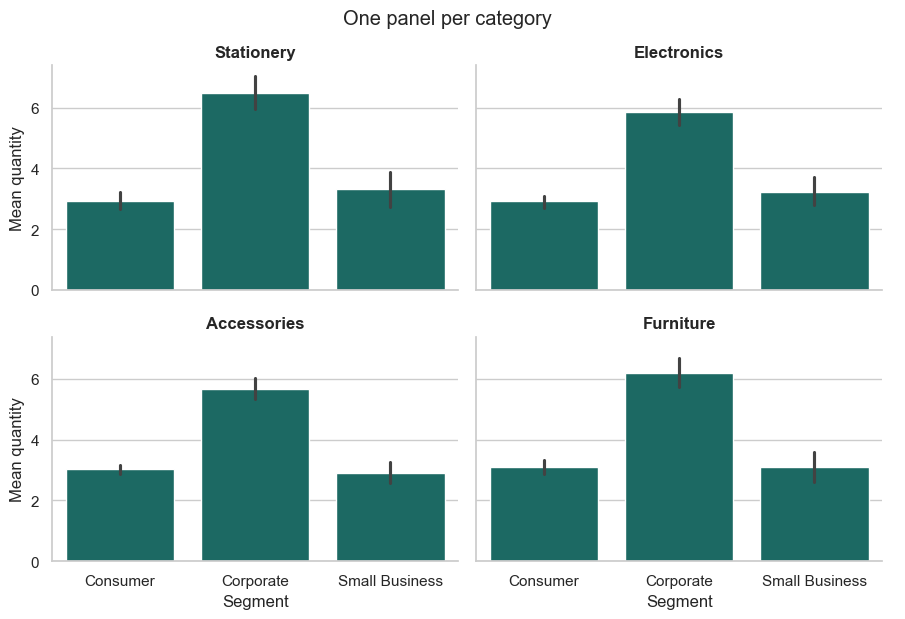

In [24]:
g = sns.catplot(data=sales, x="segment", y="quantity", col="category", col_wrap=2, kind="bar",
                order=segments, height=3, aspect=1.5)
g.set_titles("{col_name}")
g.set_axis_labels("Segment", "Mean quantity")
g.figure.suptitle("One panel per category", y=1.03)
plt.show()

Corporate buys about twice the quantity in every category, not just in one.

---
## 6. Heatmaps and pair plots

### 6.1 Heatmap of a pivot table
- **What:** a coloured table.
- **When to use:** for a pivot table, a crosstab or a correlation matrix; the eye finds the extreme cells at once.

In [25]:
pt = sales.pivot_table(index="category", columns="discount", values="profit", aggfunc="mean")
pt.round(0)

discount,0.00,0.05,0.10,0.20
category,,,,
Accessories,1714.0,1512.0,1332.0,1036.0
Electronics,10401.0,8250.0,4332.0,-1753.0
Furniture,5940.0,6026.0,5543.0,3901.0
Stationery,181.0,159.0,136.0,108.0


`annot=True` writes the numbers in, and `center=0` with a diverging `cmap` puts losses and profits on opposite colours.

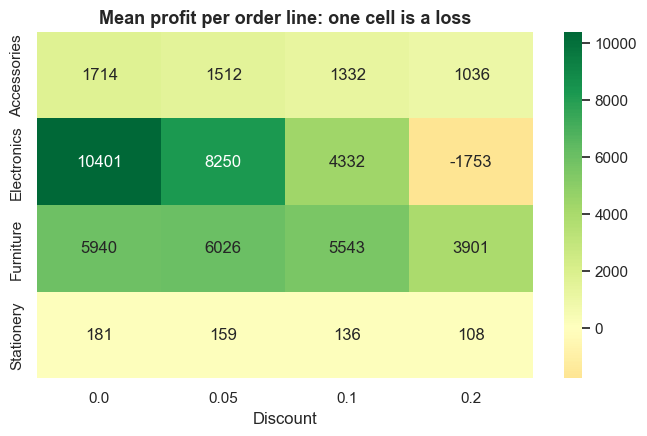

In [26]:
ax = sns.heatmap(pt, annot=True, fmt=".0f", cmap="RdYlGn", center=0)
ax.set(title="Mean profit per order line: one cell is a loss", xlabel="Discount", ylabel="")
plt.show()

### 6.2 Correlation heatmap

In [27]:
corr = sales[["quantity", "unit_price", "discount", "revenue", "profit"]].corr()
corr.round(2)

,quantity,unit_price,discount,revenue,profit
quantity,1.00,-0.00,-0.00,0.31,0.36
unit_price,-0.00,1.00,-0.00,0.81,0.58
discount,-0.00,-0.00,1.00,-0.04,-0.22
revenue,0.31,0.81,-0.04,1.00,0.80
profit,0.36,0.58,-0.22,0.80,1.00


The upper triangle repeats the lower one, so `mask=` hides it.

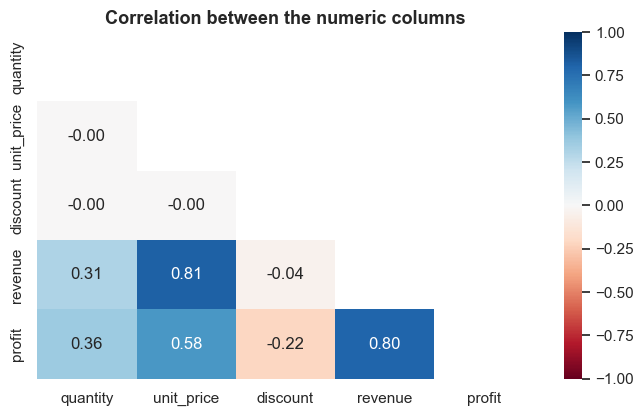

In [28]:
mask = np.triu(np.ones_like(corr, dtype=bool))

ax = sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu", center=0, vmin=-1, vmax=1)
ax.grid(False)
ax.set_title("Correlation between the numeric columns")
plt.show()

Revenue follows the **unit price** much more closely than the quantity. Discount and profit look only weakly related; Section 7.4 shows why that number is misleading.

### 6.3 Pair plot
- **What:** a scatter plot for **every pair** of numeric columns, with each column's distribution on the diagonal.
- **When to use:** as a first screen of a new dataset with only a few numeric columns.

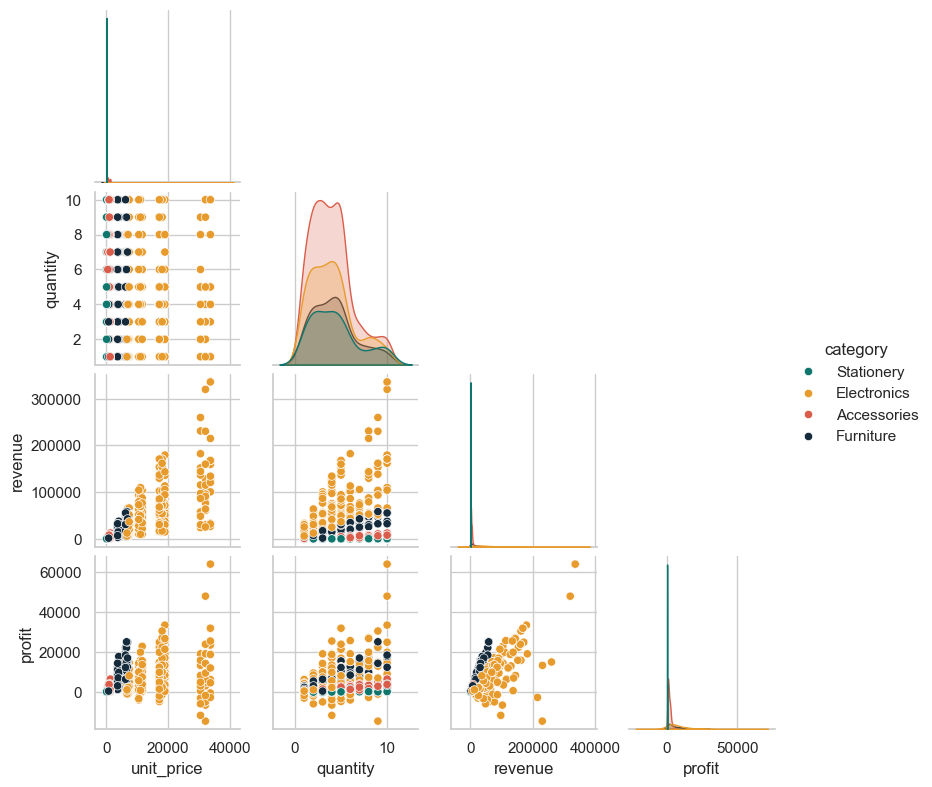

In [29]:
g = sns.pairplot(sales[["unit_price", "quantity", "revenue", "profit", "category"]], hue="category", corner=True, height=2)
plt.show()

---
## 7. Reading statistical charts

Seaborn computes quartiles, means and intervals behind the scenes. Reading those charts correctly matters as much as drawing them.

### 7.1 Reading a box plot

Take one group, the Electronics order lines, and compute what the box is made of.

In [30]:
e = sales.loc[sales["category"] == "Electronics", "revenue"]

q1, med, q3 = e.quantile([0.25, 0.5, 0.75])
iqr = q3 - q1
upper_whisker = e[e <= q3 + 1.5 * iqr].max()
lower_whisker = e[e >= q1 - 1.5 * iqr].min()
outliers = e[e > q3 + 1.5 * iqr]

print(f"Q1 {q1:,.0f} · median {med:,.0f} · Q3 {q3:,.0f} · IQR {iqr:,.0f}")
print(f"whiskers {lower_whisker:,.0f} to {upper_whisker:,.0f} · {len(outliers)} points beyond")

Q1 22,050 · median 41,800 · Q3 75,600 · IQR 53,550
whiskers 5,600 to 153,900 · 25 points beyond


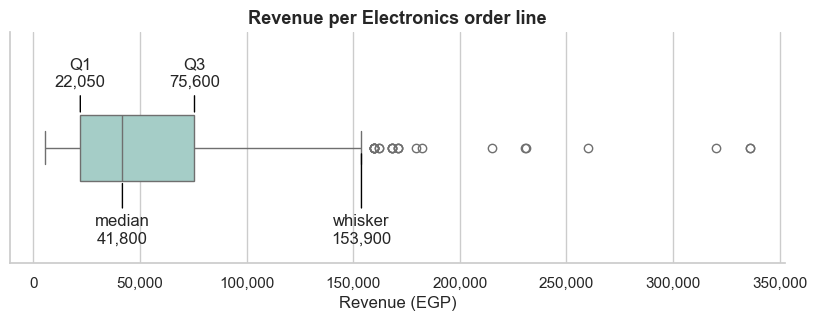

In [31]:
fig, ax = plt.subplots(figsize=(10, 3))
sns.boxplot(x=e, ax=ax, color="#9FD3CC", width=0.4)

# Q1 and Q3 labelled above the box, the median and the whisker below, so the labels don't collide
for value, label, edge, text_y in [(q1, "Q1", -0.2, -0.45), (q3, "Q3", -0.2, -0.45),
                                    (med, "median", 0.2, 0.5), (upper_whisker, "whisker", 0.02, 0.5)]:
    ax.annotate(f"{label}\n{value:,.0f}", xy=(value, edge), xytext=(value, text_y), ha="center", va="center",
                arrowprops={"arrowstyle": "-", "color": "black"})

ax.xaxis.set_major_formatter("{x:,.0f}")
ax.set(title="Revenue per Electronics order line", xlabel="Revenue (EGP)", ylim=(0.7, -0.7))
plt.show()

| Part | Meaning |
|---|---|
| box | the middle 50% of the rows, from Q1 to Q3 (its width is the IQR) |
| line in the box | the median |
| whiskers | the furthest points that are still within 1.5 × IQR of the box |
| dots | points beyond the whiskers: **potential** outliers, worth a look, not automatically errors |

A box plot is good for comparing many groups at once, but it hides the shape: a distribution with two peaks still looks like one box. When the shape matters, use a violin plot or a histogram.

### 7.2 What does the error bar mean?

The two common error bars answer different questions. Compute both by hand:

In [32]:
g = known.groupby("segment")["quantity"].agg(["mean", "std", "count"])
g["ci95"] = 1.96 * g["std"] / np.sqrt(g["count"])
g.round(2)

,mean,std,count,ci95
segment,,,,
Consumer,2.99,1.44,762,0.10
Corporate,5.94,2.53,538,0.21
Small Business,3.09,1.48,164,0.23


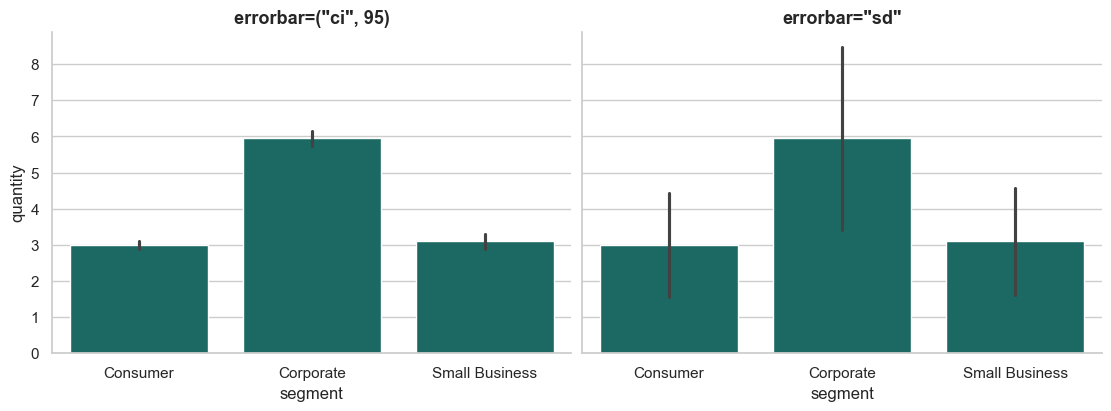

In [33]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4), sharey=True, layout="constrained")
sns.barplot(data=known, x="segment", y="quantity", order=segments, errorbar=("ci", 95), ax=axs[0])
axs[0].set_title('errorbar=("ci", 95)')
sns.barplot(data=known, x="segment", y="quantity", order=segments, errorbar="sd", ax=axs[1])
axs[1].set_title('errorbar="sd"')
plt.show()

| Error bar | Answers | With more rows |
|---|---|---|
| **95% CI** | how sure are we about the **mean**? | shrinks |
| **sd** | how spread out are the **rows**? | stays about the same |

So a short CI bar does not mean the customers are alike: Corporate quantities vary a lot between order lines, yet with this many rows the mean is known precisely. Always say which error bar a chart shows.

### 7.3 Overplotting: when dots hide dots

`quantity` is a whole number and prices repeat, so many rows land on exactly the same spot.

1,466 rows, but only 299 distinct points


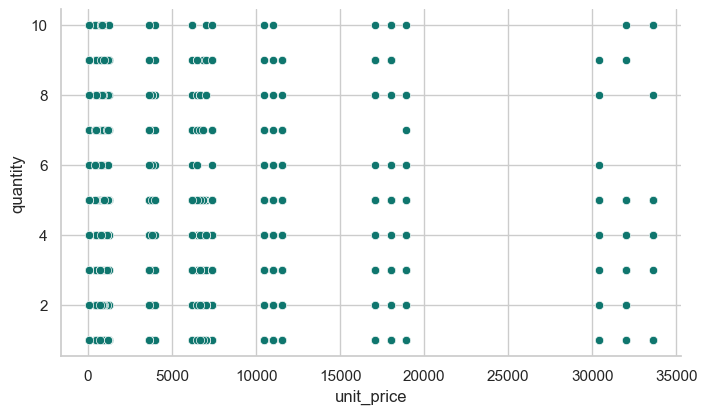

In [34]:
pts = sales[["unit_price", "quantity"]]
print(f"{len(pts):,} rows, but only {len(pts.drop_duplicates()):,} distinct points")

sns.scatterplot(data=pts, x="unit_price", y="quantity")
plt.show()

The scatter plot shows each spot once, whether one row sits there or a hundred. Ways out:

- see-through dots (`alpha=`) and smaller dots (`s=`), or a random sample;
- a 2-D histogram, which counts the rows in each cell;
- a summary per group: box, violin or heatmap.

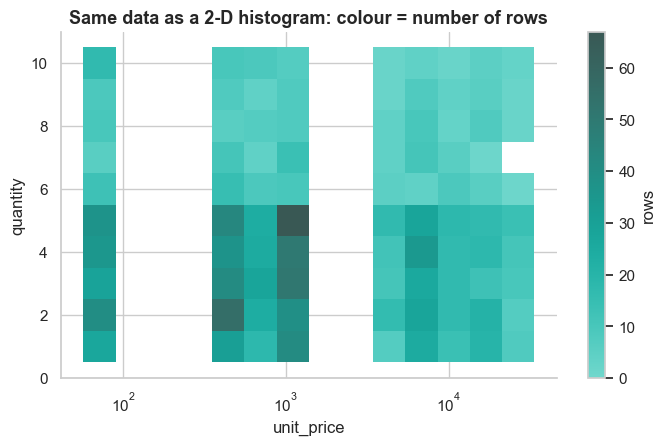

In [35]:
ax = sns.histplot(data=pts, x="unit_price", y="quantity", log_scale=(True, False), discrete=(False, True),
                  cbar=True, cbar_kws={"label": "rows"})
ax.set_title("Same data as a 2-D histogram: colour = number of rows")
plt.show()

### 7.4 One correlation can hide a group effect

Section 6.2 showed a weak correlation between discount and profit over all rows. Split it by category:

In [36]:
r_all = sales["discount"].corr(sales["profit"])
by_cat = (sales.groupby("category")[["discount", "profit"]]
          .apply(lambda t: t["discount"].corr(t["profit"]))
          .sort_values())
print(f"all rows: r = {r_all:.2f}")
by_cat.round(2)

all rows: r = -0.22


category
Electronics   -0.44
Stationery    -0.25
Accessories   -0.21
Furniture     -0.11
dtype: float64

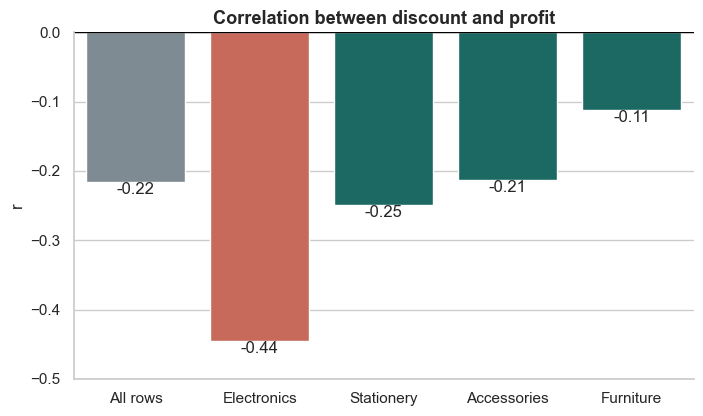

In [37]:
r = pd.concat([pd.Series({"All rows": r_all}), by_cat])
colors = ["#7C8B96"] + ["#D95D4A" if c == "Electronics" else "#0F766E" for c in by_cat.index]

ax = sns.barplot(x=r.index, y=r.values, hue=r.index, palette=colors, legend=False)
ax.axhline(0, color="black", linewidth=1)
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f")
ax.set(title="Correlation between discount and profit", xlabel="", ylabel="r", ylim=(-0.5, 0))
plt.show()

The overall r is weak, but inside Electronics the link is twice as strong: discounts eat the thin Electronics margins. The other categories, with weaker links, dilute it when everything is pooled.

Before concluding "no effect", split by group with `hue=` or `col=`.

---
## Summary

| Task | Seaborn |
|---|---|
| Scatter / line | `sns.scatterplot(hue=, alpha=)`, `sns.lineplot(hue=, marker=)` |
| Counts | `sns.countplot(x=, order=, hue=)` |
| Mean per group | `sns.barplot(x=, y=, estimator=, errorbar=("ci", 95) / "sd" / None)` |
| Distribution | `sns.histplot(log_scale=, kde=, stat="density", common_norm=False)`, `sns.kdeplot(fill=)` |
| Distribution per group | `sns.boxplot`, `sns.violinplot(inner="quart", cut=0)` |
| Panels | `sns.relplot`, `sns.catplot`, `sns.displot` with `col=`, `row=`, `col_wrap=` · `g.set_titles("{col_name}")` |
| 2-D table | `sns.heatmap(annot=True, fmt=, cmap=, center=, mask=)` |
| Dense scatter | `alpha=`, `s=`, or `sns.histplot(x=, y=, cbar=True)` |
| All pairs | `sns.pairplot(df, hue=, corner=True)` |
| Look | `sns.set_theme(style=, palette=)`, dict palette for focus |

**Reading the charts:** a box hides the shape, a CI is about the mean while sd is about the rows, dense dots hide each other, and an overall correlation can hide a group effect.

**Next:** [Plotly](04_plotly.ipynb): interactive charts.